# 01 · EDA de vivienda en Euskadi

**Unidad:** municipio y trimestre de inicio del contrato. **Objetivo observado:** renta mensual media EMAL. No son anuncios individuales ni expedientes de ayudas.

Este proyecto orienta a servicios municipales de juventud. La predicción es supervisada y de regresión; no es una resolución administrativa. Los originales se capturan con `scripts/capture_sources.py` y se verifican mediante SHA-256.

In [1]:
from pathlib import Path
import sys, os, json
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'AGENTS.md').exists())
sys.path.insert(0, str(ROOT))
OUT = Path(os.getenv('RETO1_ARTIFACT_DIR', str(ROOT / 'entrega_ml')))
from src.ml_data import read_emal, temporal_split, FEATURES, TARGET
from src.ml_workflow import make_eda
frame, procedencia = read_emal(ROOT / 'data/capturas_oficiales')
train, val, test = temporal_split(frame)
if (OUT / 'data/procedencia.json').exists():
    anterior = json.loads((OUT / 'data/procedencia.json').read_text())
    assert anterior['fuente']['sha256'] == procedencia['fuente']['sha256'], 'La fuente ha cambiado: no mezclar entregas'
display(procedencia)
display(train.head())

{'fuente': {'archivo': 'emal_municipios.xlsx',
  'url_solicitada': 'https://opendata.euskadi.eus/contenidos/estadistica/122417_emal_tablas_estad/opendata/EMAL.-Barrios-Municipios.-2016-2026_es.xlsx',
  'fecha_utc': '2026-11-10T14:37:18.098528+00:00',
  'http_status': 200,
  'url_final': 'https://opendata.euskadi.eus/contenidos/estadistica/122417_emal_tablas_estad/opendata/EMAL.-Barrios-Municipios.-2016-2026_es.xlsx',
  'estado': 'descargado',
  'bytes': 256980,
  'sha256': 'f4d27d4e8e9bd3688d4e7a454026a4a0884073dc73e3fc1c0da4891a1ad1af5c'},
 'unidad': 'municipio/trimestre; nuevos contratos EMAL',
 'observaciones': 768,
 'municipios': 19,
 'objetivos_no_publicados_excluidos': 11,
 'exclusion_territorial': '48036 Galdakao: cambio de perimetro',
 'advertencia': 'Serie revisada en la fecha de captura; evaluacion retrospectiva, no prueba de disponibilidad historica en tiempo real. No representa anuncios individuales ni todos los municipios de Euskadi.',
 'smote': 'No aplicable al objetivo c

,codigo_municipio,municipio,anio,trimestre,renta_media_eur,numero_contratos,periodo,renta_lag1,renta_lag4,contratos_lag1,provincia
0,01059,Vitoria-Gasteiz,2016,1,549.06,428.0,8064,NaN,NaN,NaN,Araba
1,20030,Eibar,2016,1,514.58,63.0,8064,NaN,NaN,NaN,Gipuzkoa
2,20040,Hernani,2016,1,597.44,39.0,8064,NaN,NaN,NaN,Gipuzkoa
3,20045,Irun,2016,1,598.29,163.0,8064,NaN,NaN,NaN,Gipuzkoa
4,20055,Arrasate/Mondragon,2016,1,515.71,21.0,8064,NaN,NaN,NaN,Gipuzkoa


## Campos y calidad

`codigo_municipio` conserva cinco dígitos; `municipio` y `provincia` identifican el territorio; `anio` y `trimestre` definen la observación; `numero_contratos` mide fianzas del trimestre; `renta_media_eur` es el objetivo. `renta_lag1`, `renta_lag4` y `contratos_lag1` son datos de trimestres anteriores, nunca del trimestre a predecir.

Se excluyen totales territoriales, stocks vigentes actualizados por IRAV y Galdakao por el cambio de perímetro. El guion de EMAL indica falta de publicación/oferta suficiente, no cero. Los objetivos ausentes se excluyen, **no se imputan**. No se eliminan rentas altas arbitrariamente.

In [2]:
display(pd.DataFrame({'tipo': train.dtypes.astype(str), 'nulos_pct_train': train.isna().mean() * 100}))
assert not frame.duplicated(['codigo_municipio', 'periodo']).any()
print('Filas train / validación / test reservado:', len(train), len(val), len(test))
print('Variables de entrada:', FEATURES)
print('Objetivo:', TARGET)
print('Duplicados municipio/trimestre:', frame.duplicated(['codigo_municipio', 'periodo']).sum())

,tipo,nulos_pct_train
codigo_municipio,object,0.000000
municipio,object,0.000000
anio,int64,0.000000
trimestre,int64,0.000000
renta_media_eur,float64,0.000000
numero_contratos,float64,0.000000
periodo,int64,0.000000
renta_lag1,float64,4.159734
renta_lag4,float64,13.643927
contratos_lag1,float64,2.995008


Filas train / validación / test reservado: 601 75 92
Variables de entrada: ['anio', 'trimestre', 'renta_lag1', 'renta_lag4', 'contratos_lag1', 'codigo_municipio', 'provincia']
Objetivo: renta_media_eur
Duplicados municipio/trimestre: 0


## Nulos y separación temporal

Los primeros retardos son nulos por construcción y la supresión de EMAL depende de la oferta: no suponemos ausencia al azar. `SimpleImputer` y `StandardScaler` se ajustan dentro de cada fold; `OneHotEncoder(handle_unknown='ignore')` mantiene la inferencia estable.

Entrenamiento: hasta 2023. Validación: 2024. Test reservado: desde 2025. La serie fue revisada en la fecha de captura: esta es una evaluación retrospectiva, no una reconstrucción de lo que se sabía en cada fecha histórica.

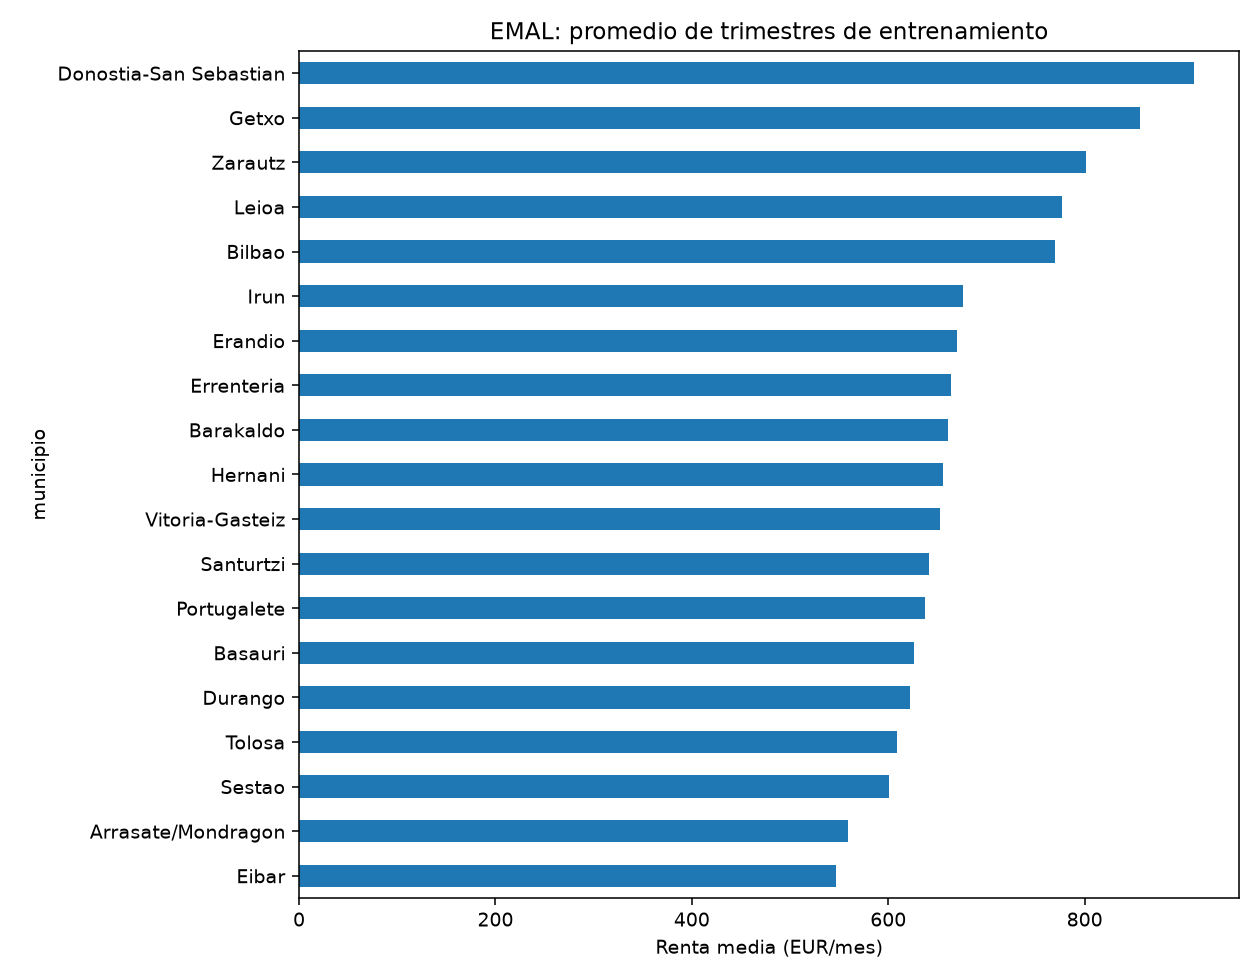

Donostia-San Sebastian presenta la mayor media de train (911.58 EUR). Es una media de agregados trimestrales, no ponderada por contratos.

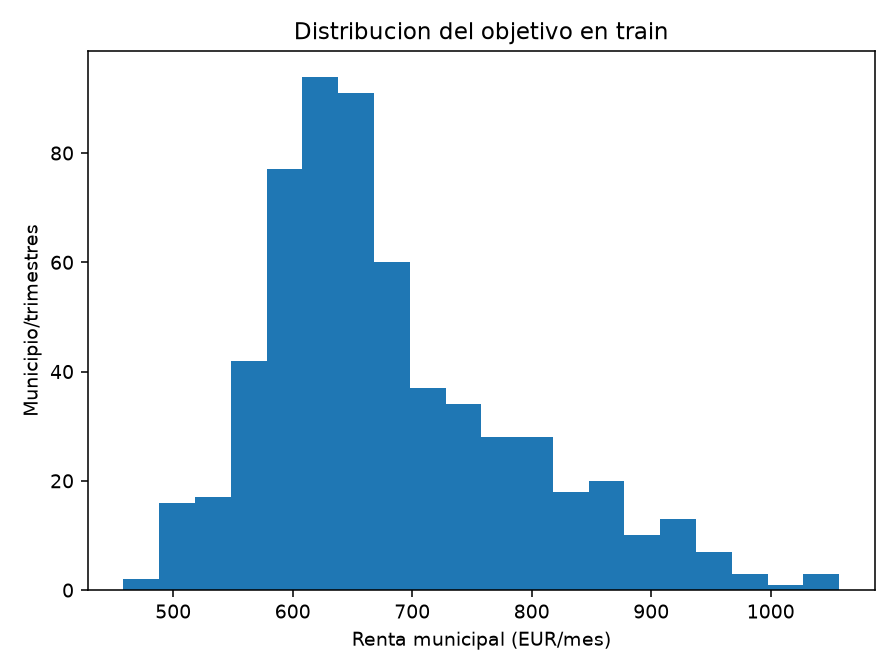

La mediana de train es 656.00 EUR. El objetivo es una renta municipal observada, no la viabilidad de una persona.

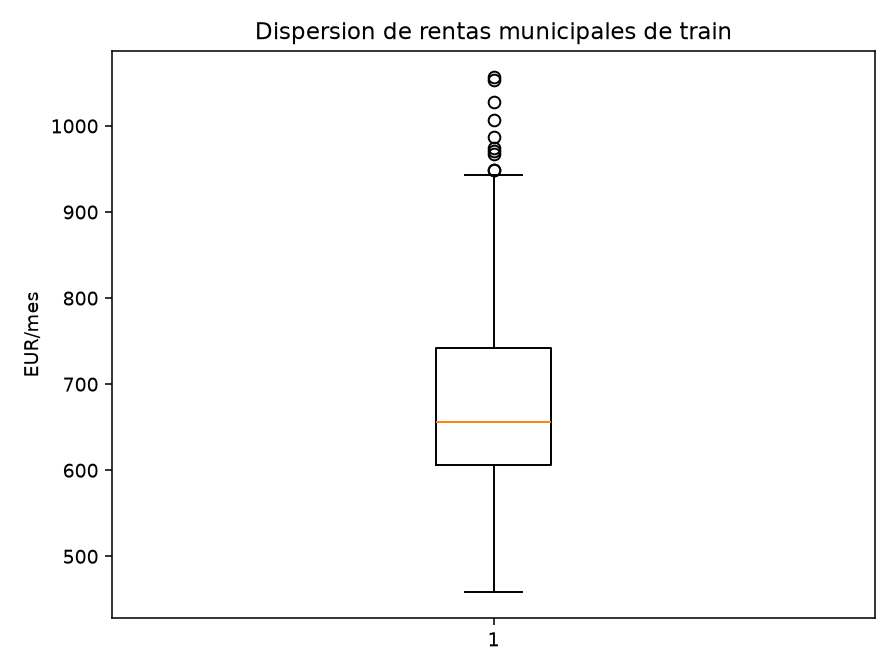

IQR = 136.13 EUR. No se eliminan precios altos solo por ser extremos: pueden reflejar diferencias territoriales reales.

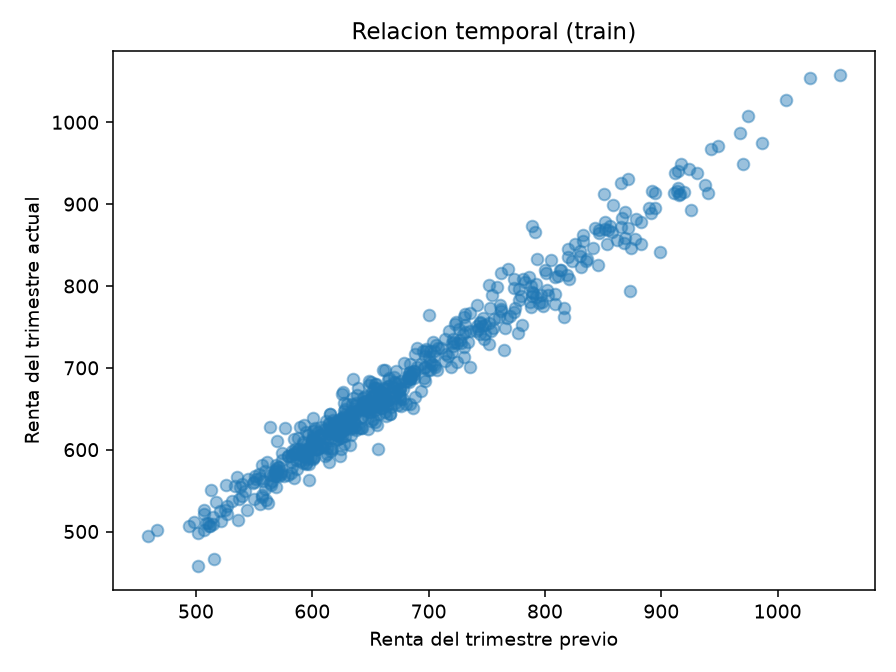

Correlacion lag1/objetivo = 0.985. La persistencia debe ser un baseline; correlacion no demuestra causalidad.

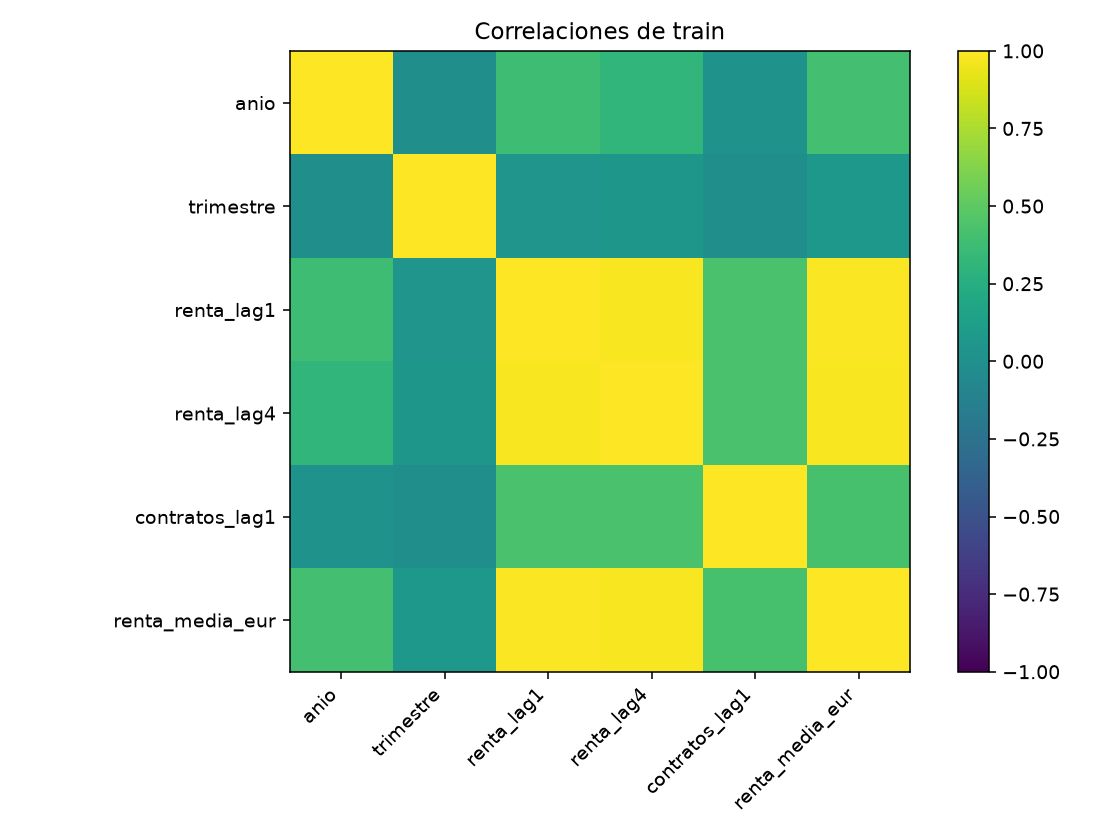

Los retardos recogen persistencia. Ni la renta actual, ni su precio/m2, ni una categoria derivada del objetivo se incluyen entre las entradas.

Los '-' de EMAL significan no disponible/oferta insuficiente. Los retardos iniciales faltan por construccion. Se conserva el patron; las medianas y categorias se ajustan dentro de cada fold, nunca con test.

In [3]:
notas = make_eda(train, OUT / 'resultados')
for archivo, conclusion in notas.items():
    if archivo.endswith('.png'):
        display(Image(filename=str(OUT / 'resultados' / archivo)))
    display(Markdown(conclusion))

## Conclusión del EDA

La persistencia temporal y las diferencias entre municipios justifican comparar un baseline de renta anterior con modelos supervisados. No utilizamos renta actual, precio/m² actual ni categorías creadas a partir del objetivo como entradas. El EDA comentado se basa en entrenamiento; el test no se emplea para decidir transformaciones.